In [6]:
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.sparse as sp
import numpy as np
from os.path import join
import os
from matplotlib.colors import ListedColormap

In [7]:
combined_data_annotated = sc.read_h5ad('/local/hailey/PLX/all_samples_bin100_process_anno.h5ad')

In [8]:
meta = pd.read_csv('/local/hailey/PLX/all_samples_bin100_process_meta.csv', index_col=0)
combined_data_annotated.obs = meta  #domain annotation --- 'domains_c' column


In [9]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.unicode_minus": False,
})

In [ ]:
#Domain Process Steps; no need to run again
# Calculate QC metrics
sc.pp.calculate_qc_metrics(combined_data, percent_top=None, log1p=False, inplace=True)

# Normalize the expression matrix to 10k reads per cell
sc.pp.normalize_total(combined_data, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(combined_data)

# Save the raw data
combined_data.raw = combined_data

# Find highly variable genes
sc.pp.highly_variable_genes(combined_data, min_mean=0.0125, max_mean=3, min_disp=0.5)

combined_data = combined_data[:, combined_data.var.highly_variable]
sc.pp.scale(combined_data, max_value=10)
sc.tl.pca(combined_data, svd_solver='arpack')
sc.external.pp.harmony_integrate(combined_data, "Sample")

# Compute the neighborhood graph
sc.pp.neighbors(combined_data, use_rep='X_pca_harmony')
sc.tl.umap(combined_data)

/tmp/ipykernel_3783787/3071648734.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/home/hailey/conda/envs/st/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


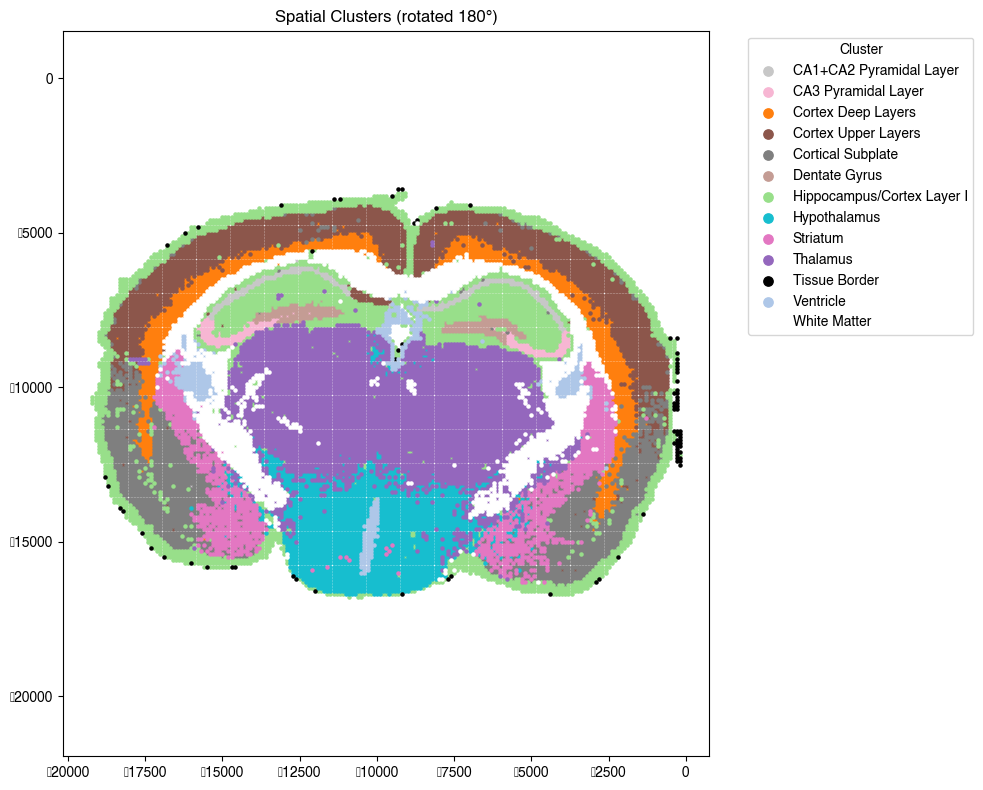

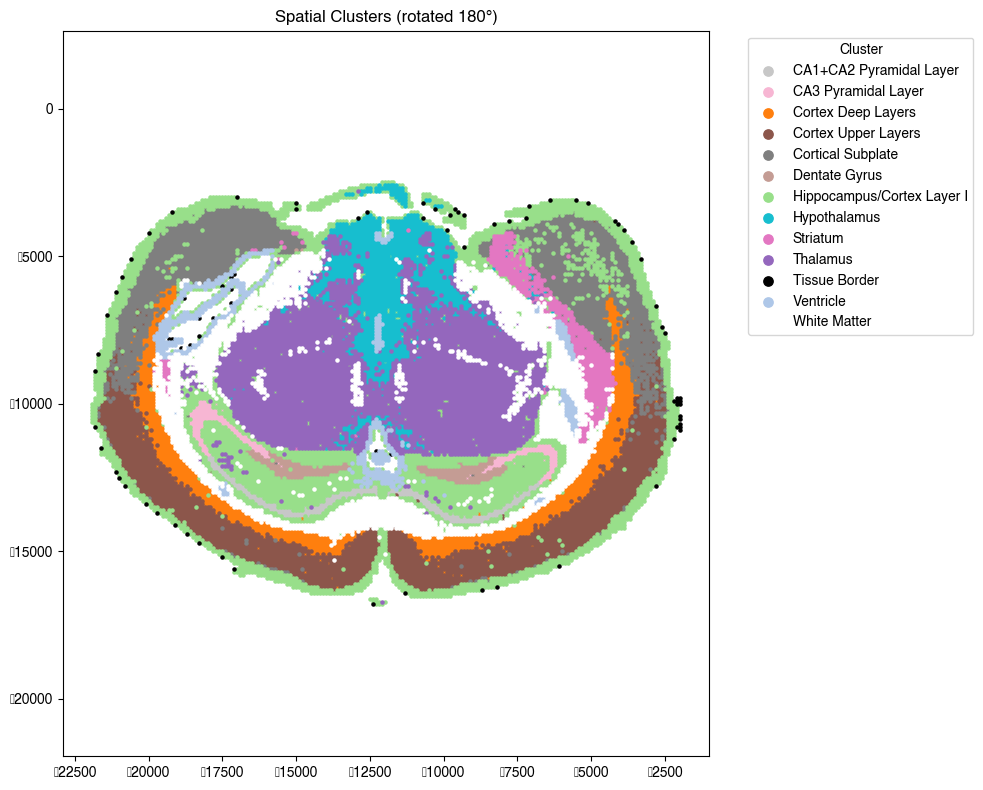

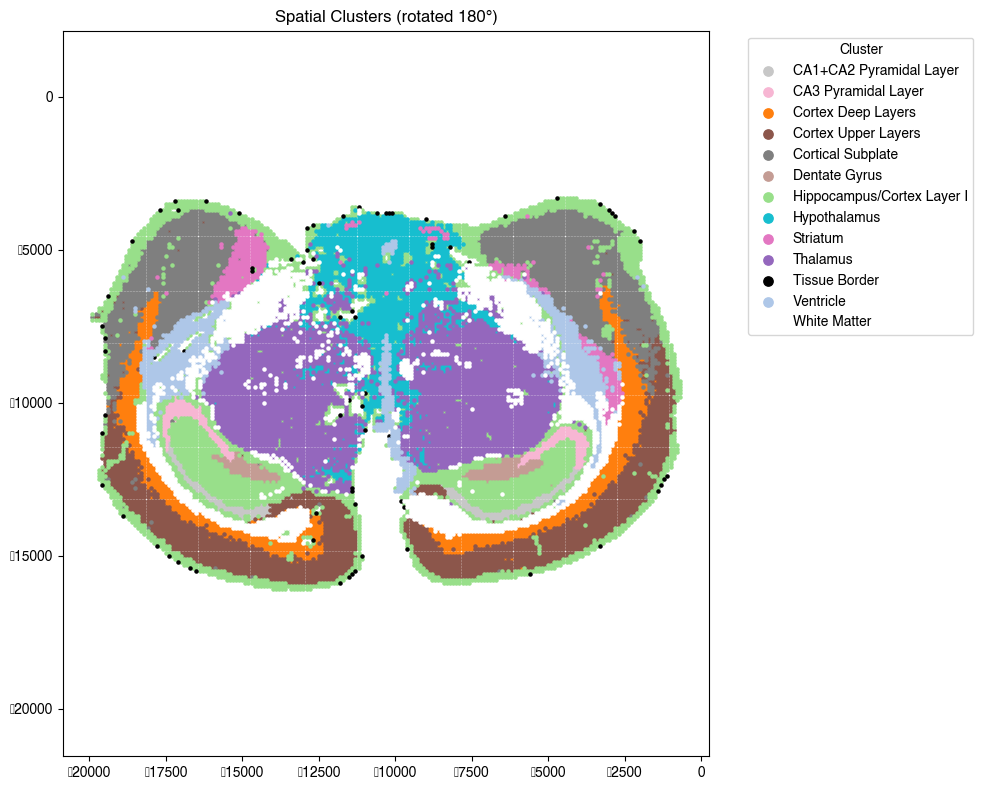

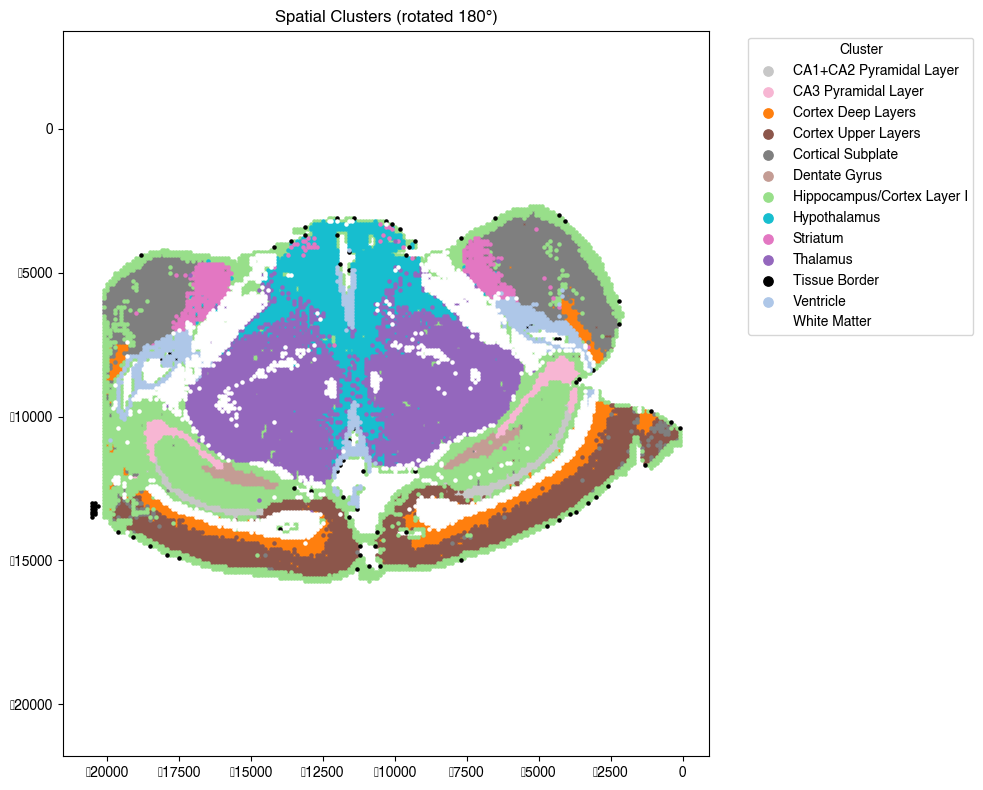

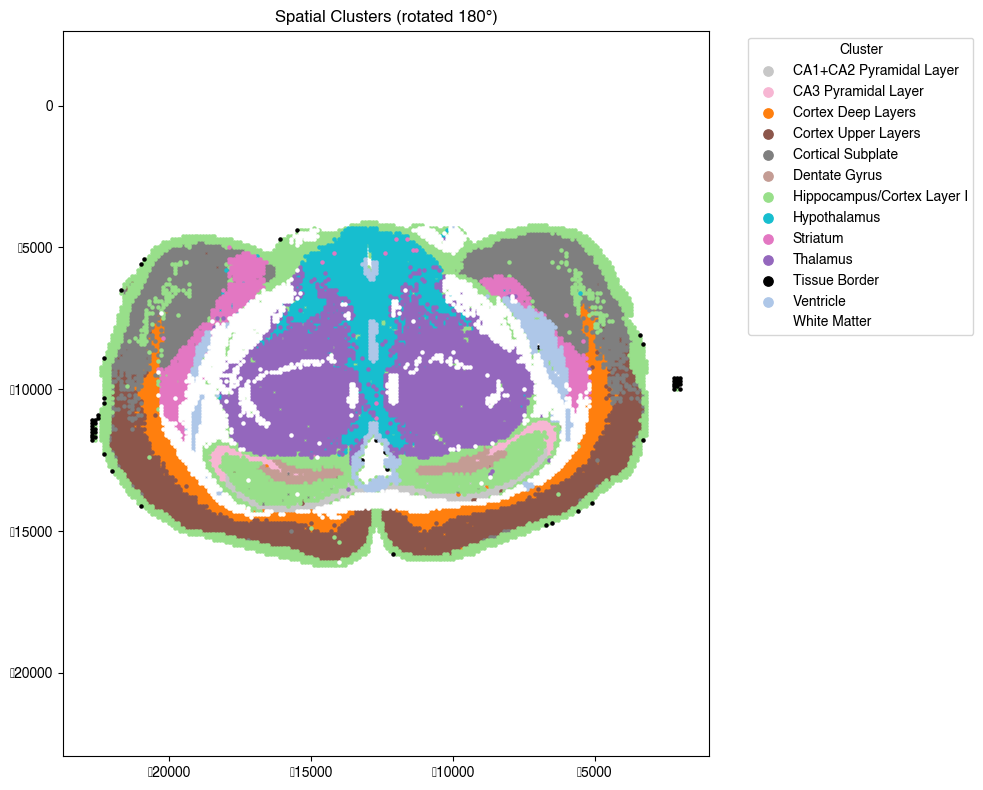

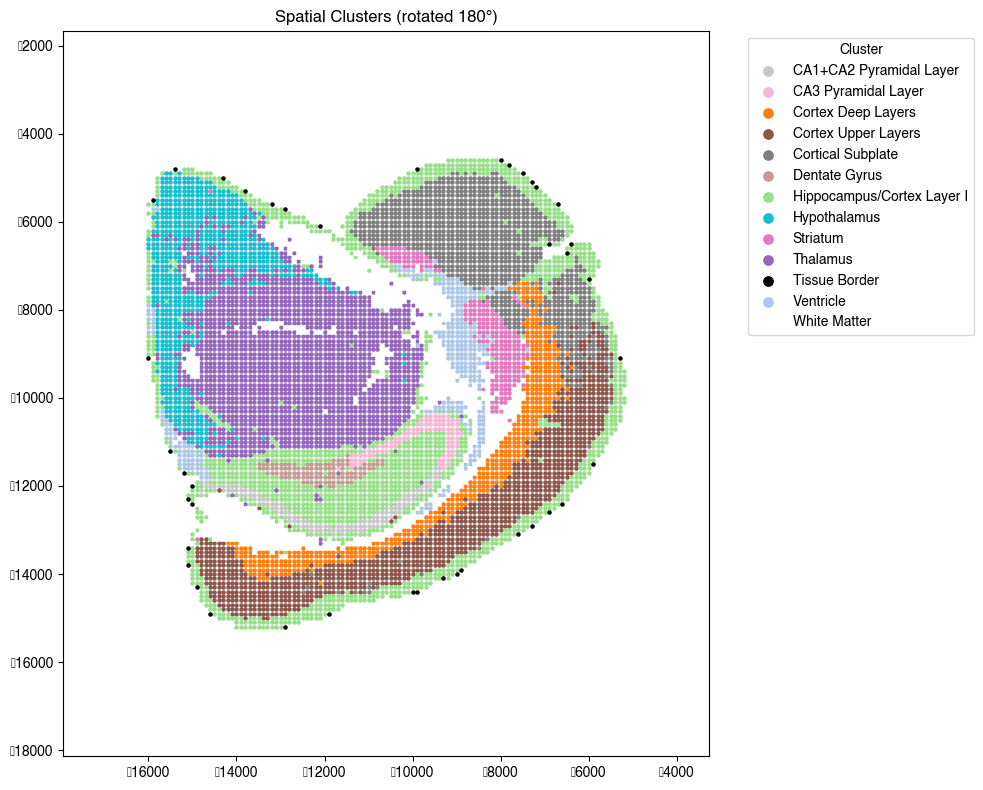

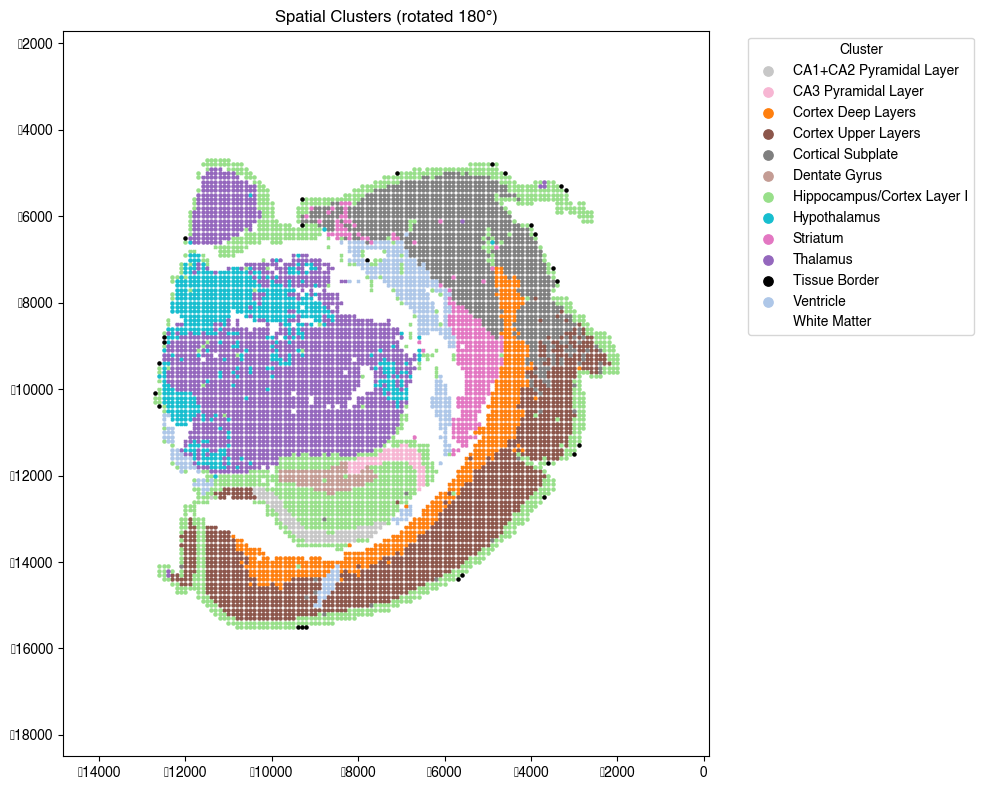

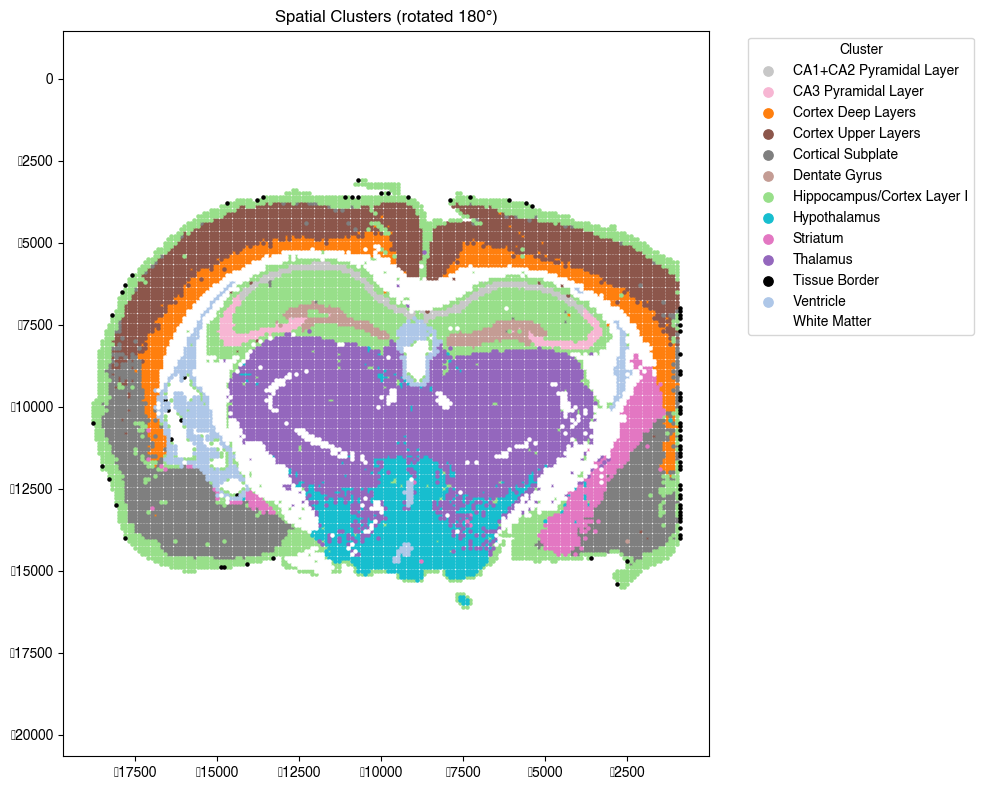

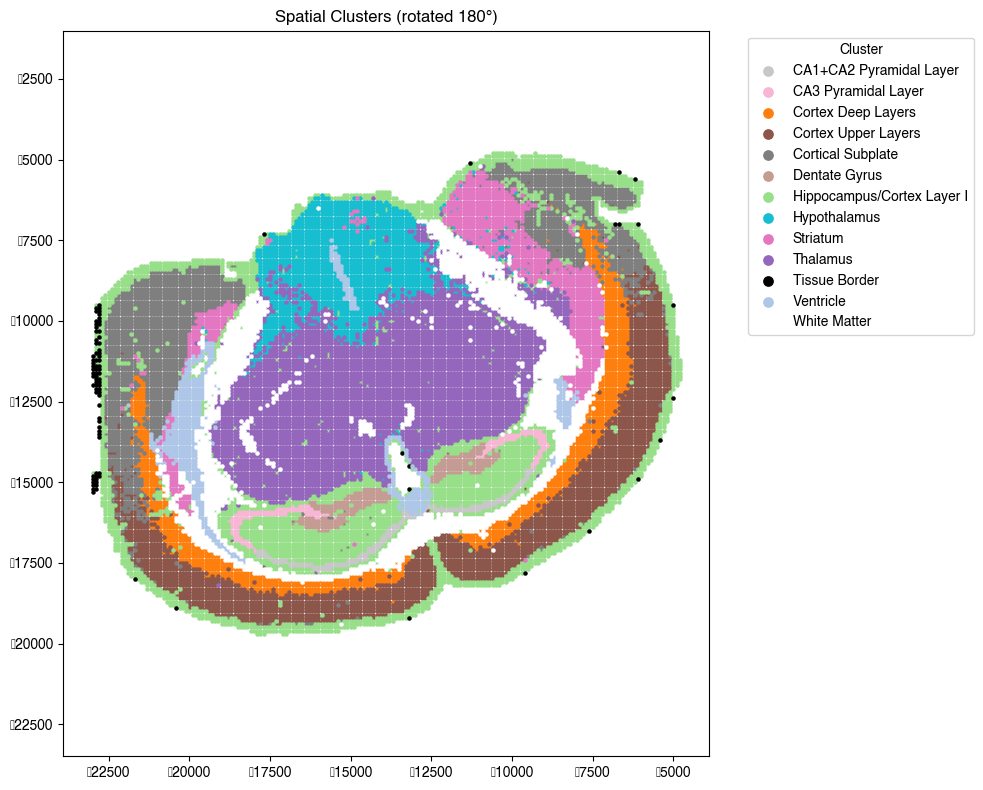

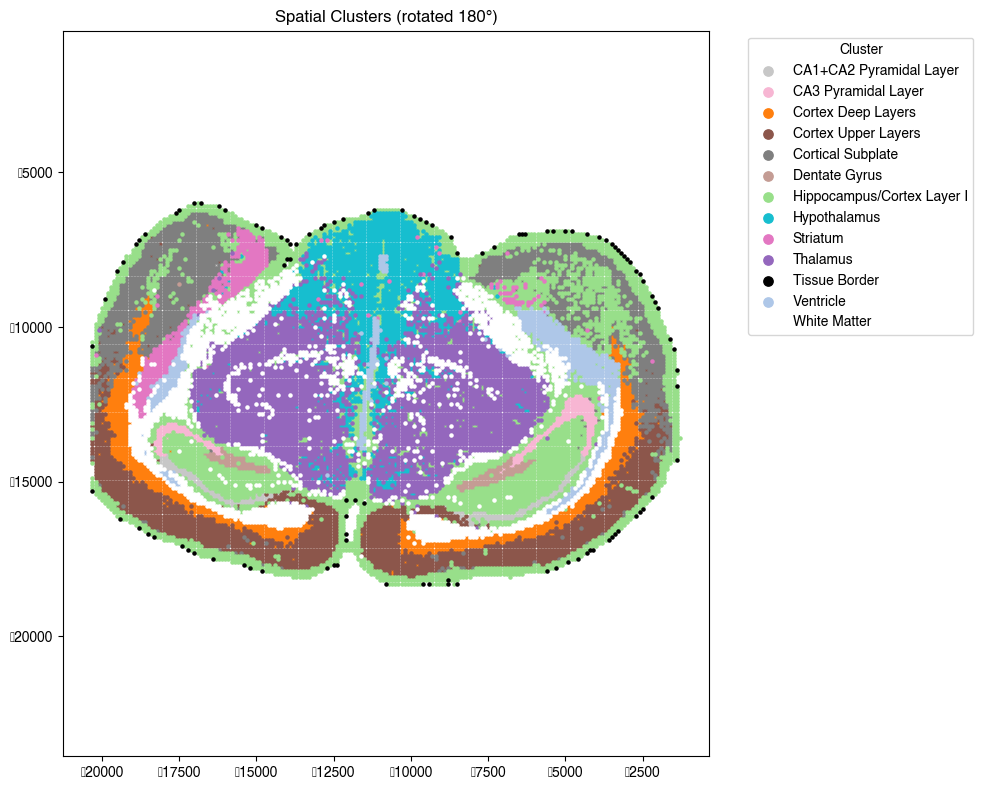

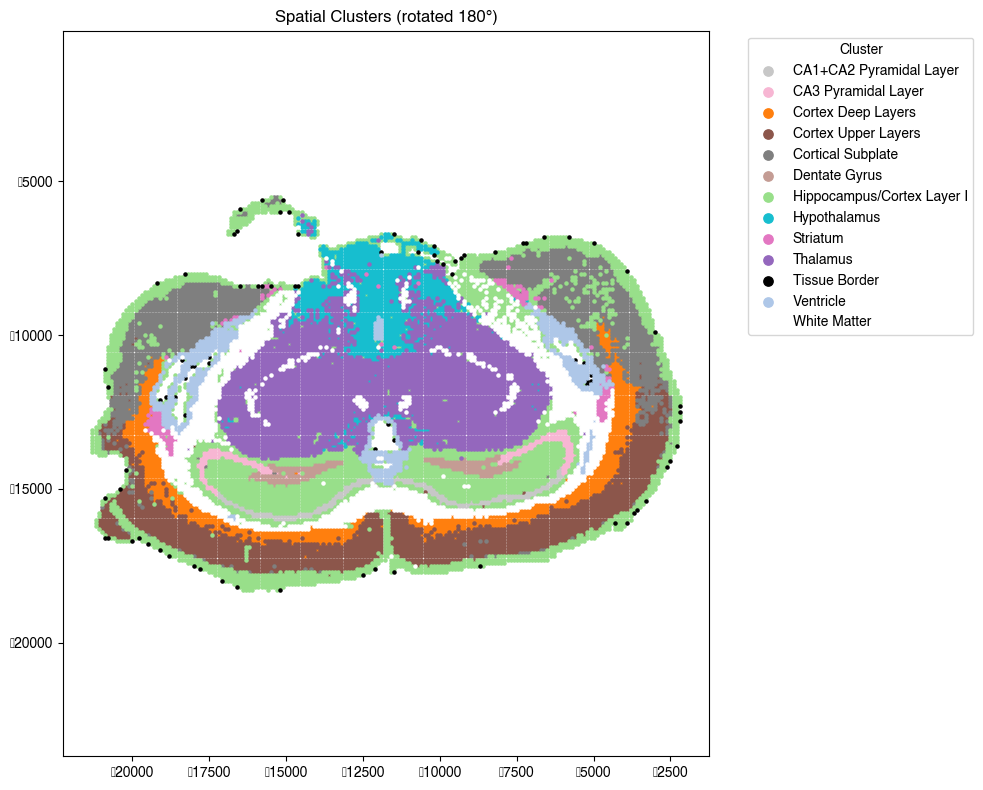

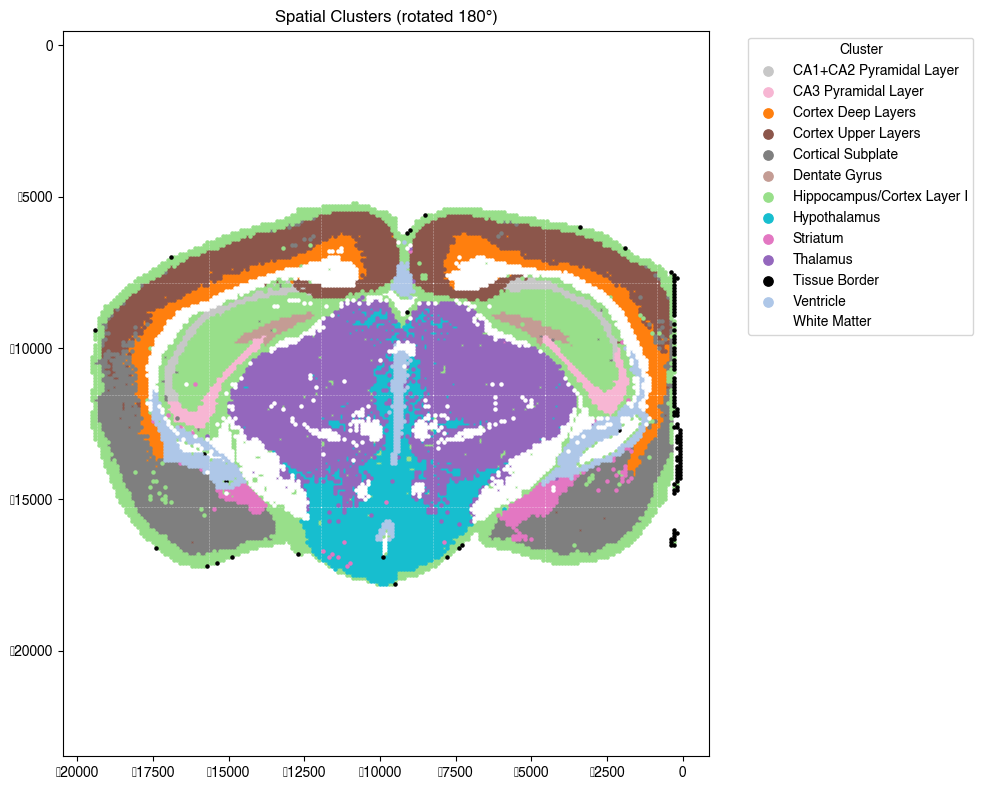

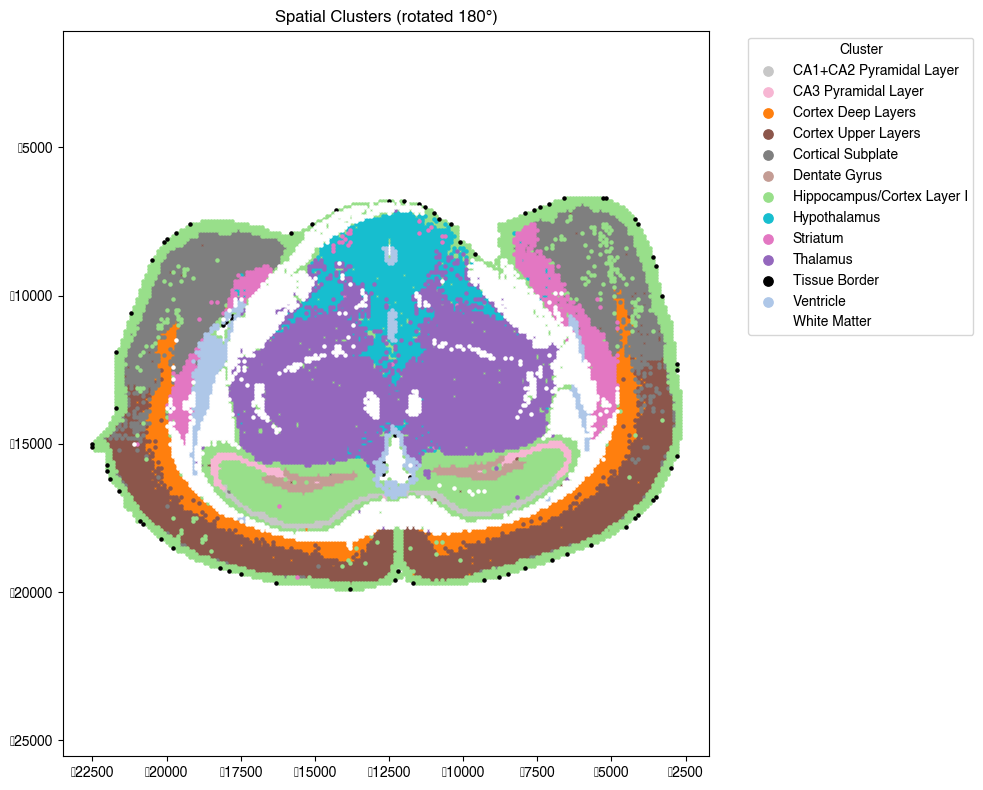

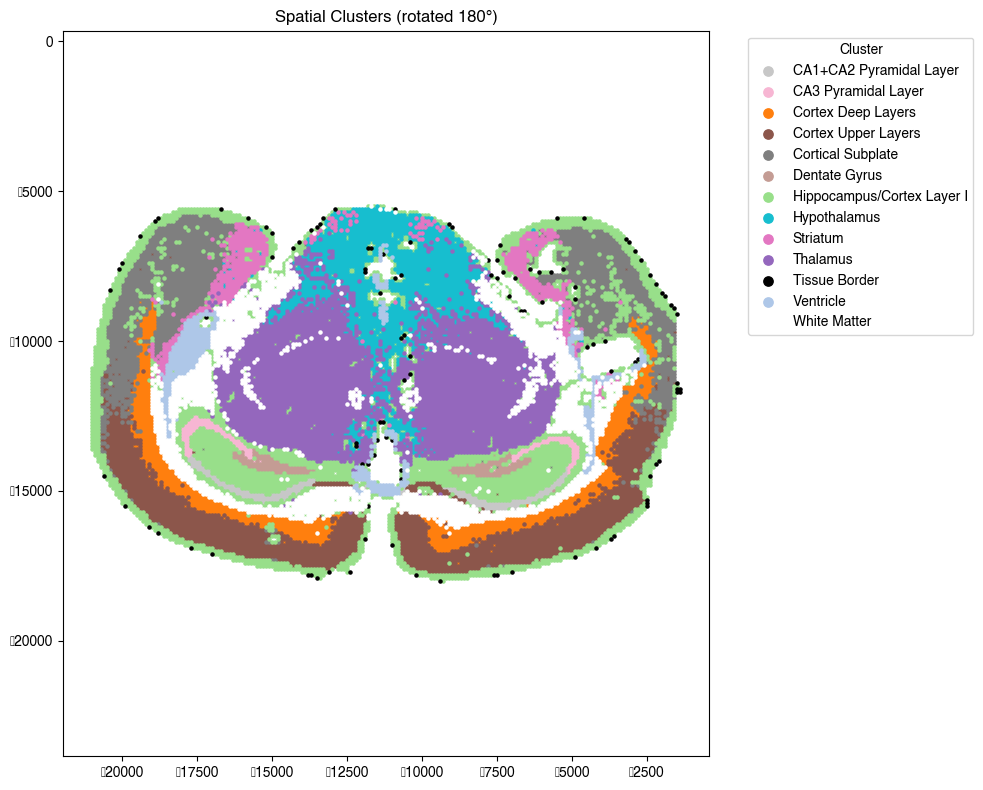

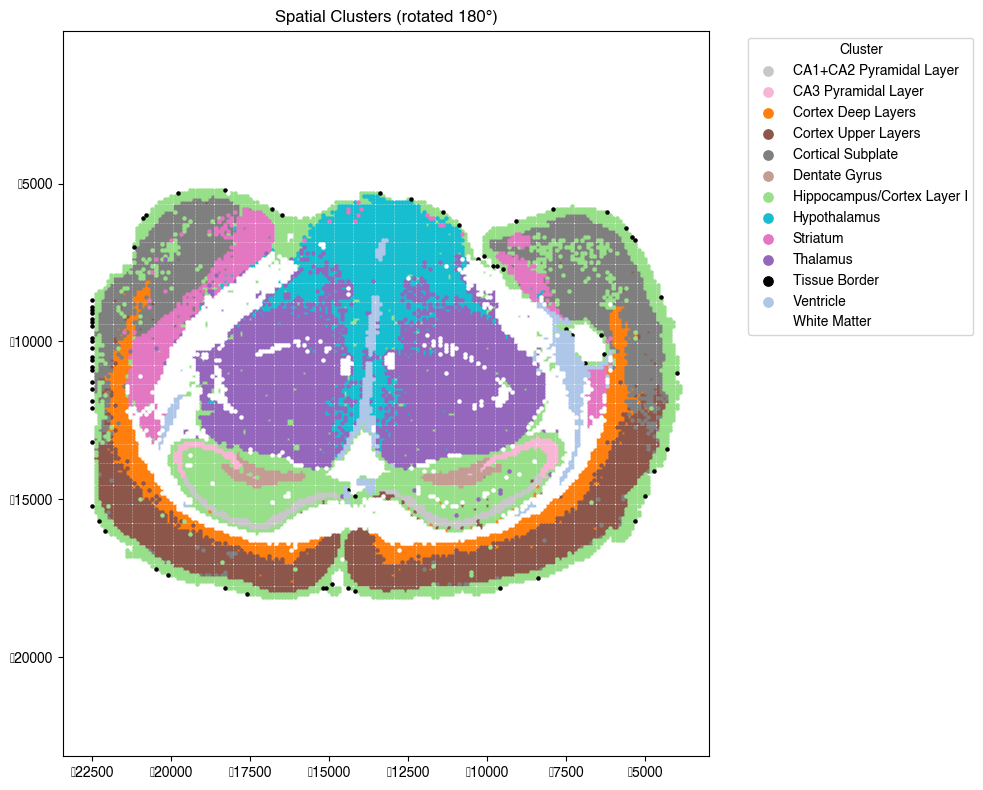

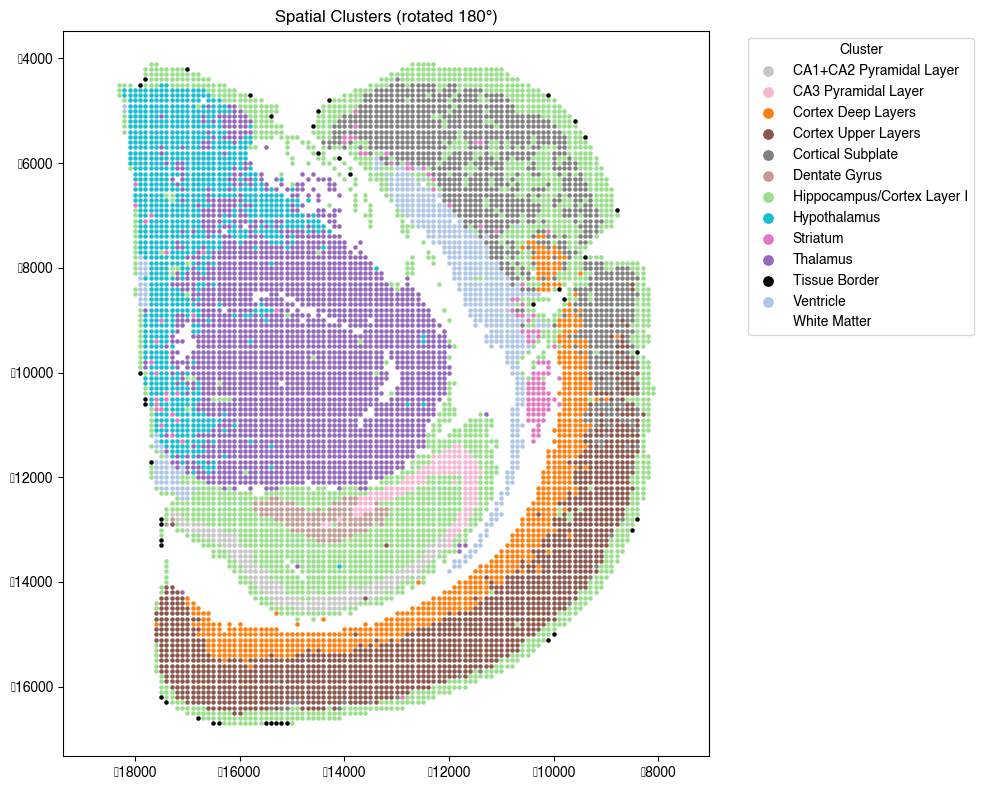

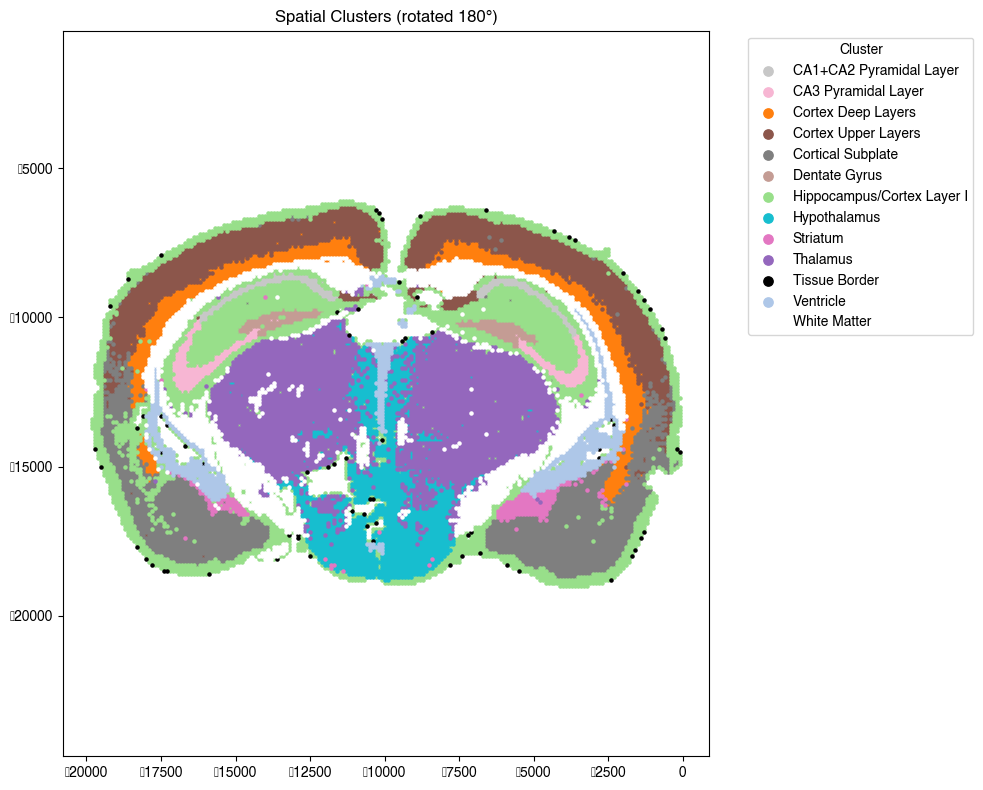

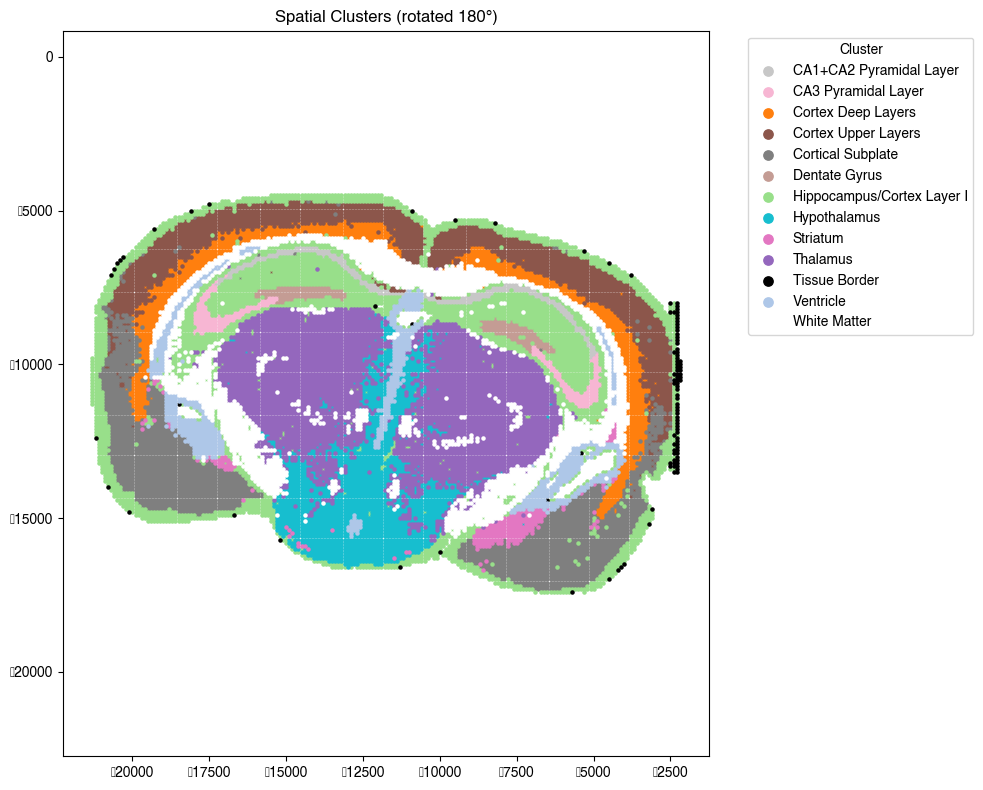

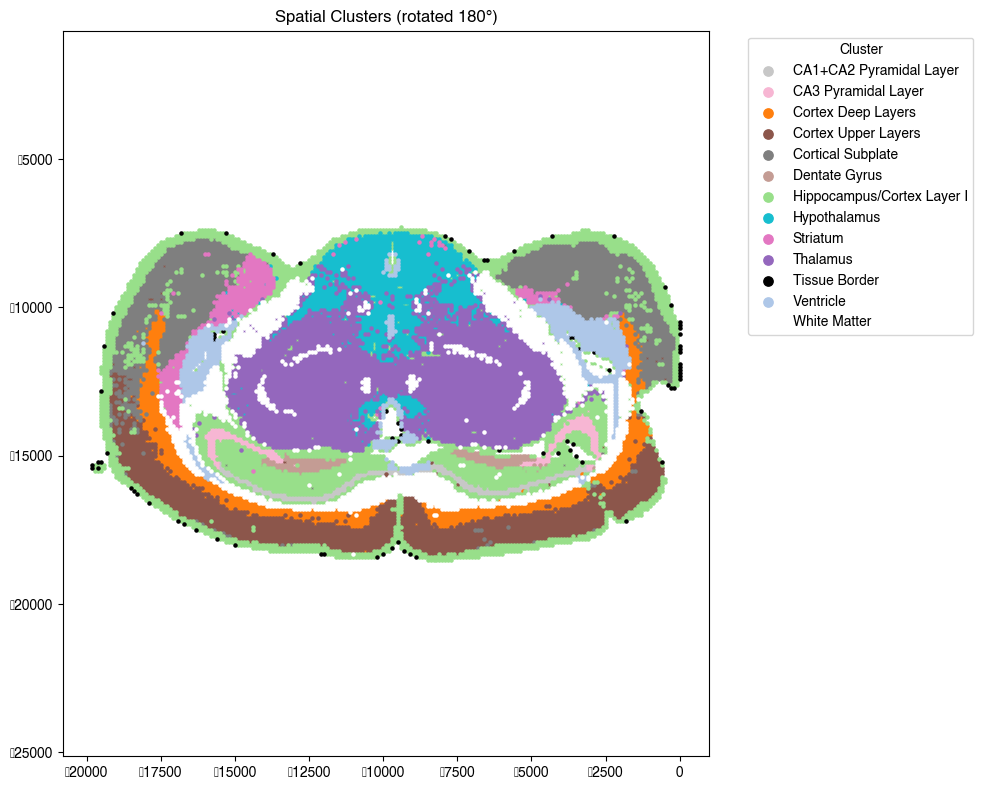

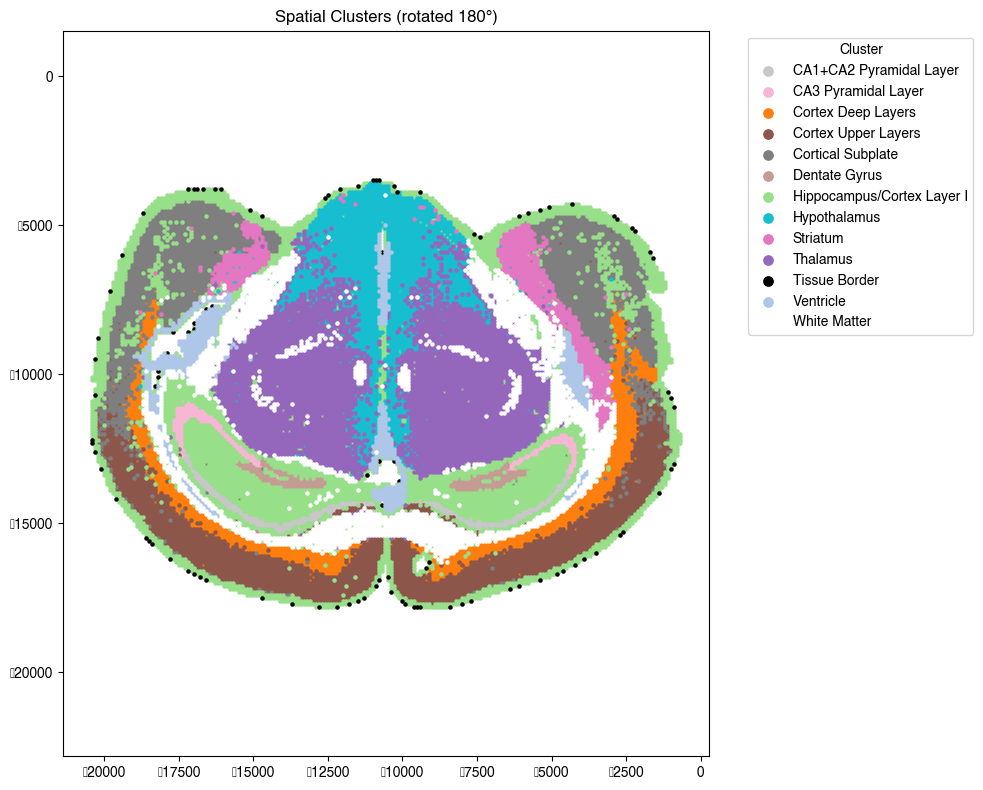

In [10]:
#figure 3D
brain_colors = {
    'White Matter': '#ffffff',              # white
    'Cortical Subplate': '#7f7f7f',         # neutral gray
   # 'Thalamus II': '#1f77b4',               # blue
    'Hypothalamus': '#17becf',            # cyan
    'Thalamus': '#9467bd',                # purple
    'Hippocampus': '#2ca02c',               # green
    'Cortex Deep Layers': '#ff7f0e',        # orange
    'Cortex Upper Layers': '#8c564b',       # brown
    'Tissue Border': '#000000',             # black
    'Striatum': '#e377c2',                  # pink
    #'Thalamus III': '#bcbd22',              # olive
    'Ventricle': '#aec7e8',               # light blue
    #'Ventricle II': '#c5dbf1',              # very light blue
    'Dentate Gyrus': '#c49c94',             # light brown
    'CA3 Pyramidal Layer': '#f7b6d3',       # light pink
    'CA1+CA2 Pyramidal Layer': '#c7c7c7',   # light gray
    #'Hypothalamus II': '#dbdb8d',           # light olive
    #'Thalamus IV': '#9edae5',               # light cyan
    #'Thalamus V': '#393b79',                # dark blue
    'Hippocampus/Cortex Layer I': '#98df8a' # light green
}

def plot_spatial_clusters(adata, cluster_key='leiden', rotation=0, figsize=(10, 8), s=1, show_legend=True, color_dict=None):
    """
    Simple function to plot spatial clusters with optional rotation and alphabetically ordered legend
    """
    import numpy as np
    import matplotlib.pyplot as plt
    
    # Get coordinates
    x = adata.obsm['spatial'][:, 0]
    y = adata.obsm['spatial'][:, 1]
    
    # Apply rotation if specified
    if rotation != 0:
        angle = np.radians(rotation)
        x_rot = x * np.cos(angle) - y * np.sin(angle)
        y_rot = x * np.sin(angle) + y * np.cos(angle)
        x, y = x_rot, y_rot
    
    # Get clusters
    clusters = adata.obs[cluster_key]
    
    # Sort clusters alphabetically for consistent legend ordering
    unique_clusters = sorted(clusters.unique())
    
    # Plot each cluster separately to ensure legend matches
    fig, ax = plt.subplots(figsize=figsize)
    
    for cluster in unique_clusters:
        mask = clusters == cluster
        if color_dict:
            color = color_dict.get(str(cluster), '#808080')  # default to gray if not found
            ax.scatter(x[mask], y[mask], s=s, label=str(cluster), color=color)
        else:
            ax.scatter(x[mask], y[mask], s=s, label=str(cluster))
    
    if show_legend:
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Cluster', markerscale=3)
    
    ax.set_title(f'Spatial Clusters (rotated {rotation}°)')
    ax.axis('equal')
    plt.tight_layout()
    plt.show()
for i in range(1, 21):
    combined_data_annotated_subset = combined_data_annotated[combined_data_annotated.obs["Sample"] == f"PLX{i}"]
    plot_spatial_clusters(combined_data_annotated_subset, 
                         cluster_key="domains_c", 
                         rotation=180, 
                         show_legend=True, 
                         color_dict=brain_colors,
                         s=5)



In [11]:
#figure 3D
def plot_spatial_scatter(
    adata,
    color_col="domains_c",
    color_dict=None,
    s=5,
    rotation=180,
    show_legend=True,
    legend_ncol=1,
    ax=None,
):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.2, 4.2))
    else:
        fig = ax.figure

    xy = adata.obsm["spatial"]
    x = xy[:, 0]
    y = xy[:, 1]

    lab = adata.obs[color_col].astype("category")
    cats = lab.cat.categories.tolist()

    if color_dict is None:
        color_dict = {c: None for c in cats}

    for c in cats:
        m = (lab.values == c)
        if m.sum() == 0:
            continue
        ax.scatter(
            x[m], y[m],
            s=s,
            c=color_dict.get(c, None),
            label=str(c),
            linewidths=0
        )

    ax.set_aspect("equal")
    ax.axis("off")

    if rotation == 180:
        ax.invert_xaxis()
        ax.invert_yaxis()

    if show_legend:
        ax.legend(
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=False,
            ncol=legend_ncol,
            markerscale=2.0,
        )

    return fig, ax

out_dir = "spatialmaps_PLX"
os.makedirs(out_dir, exist_ok=True)
print("Saving to:", os.path.abspath(out_dir))

for i in range(1, 21):
    sample = f"PLX{i}"
    ad = combined_data_annotated[combined_data_annotated.obs["Sample"] == sample].copy()
    if ad.n_obs == 0:
        print(f"[skip] {sample}: no spots")
        continue

    fig, ax = plot_spatial_scatter(
        ad,
        color_col="domains_c",
        color_dict=brain_colors,
        s=5,
        rotation=180,
        show_legend=True,
    )

    save_path = os.path.join(out_dir, f"{sample}_domains_c.png")
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print("[saved]", save_path)


Saving to: /home/hailey/PLX/Code_Figures/spatialmaps_PLX
[saved] spatialmaps_PLX/PLX1_domains_c.png
[saved] spatialmaps_PLX/PLX2_domains_c.png
[saved] spatialmaps_PLX/PLX3_domains_c.png
[saved] spatialmaps_PLX/PLX4_domains_c.png
[saved] spatialmaps_PLX/PLX5_domains_c.png
[saved] spatialmaps_PLX/PLX6_domains_c.png
[saved] spatialmaps_PLX/PLX7_domains_c.png
[saved] spatialmaps_PLX/PLX8_domains_c.png
[saved] spatialmaps_PLX/PLX9_domains_c.png
[saved] spatialmaps_PLX/PLX10_domains_c.png
[saved] spatialmaps_PLX/PLX11_domains_c.png
[saved] spatialmaps_PLX/PLX12_domains_c.png
[saved] spatialmaps_PLX/PLX13_domains_c.png
[saved] spatialmaps_PLX/PLX14_domains_c.png
[saved] spatialmaps_PLX/PLX15_domains_c.png
[saved] spatialmaps_PLX/PLX16_domains_c.png
[saved] spatialmaps_PLX/PLX17_domains_c.png
[saved] spatialmaps_PLX/PLX18_domains_c.png
[saved] spatialmaps_PLX/PLX19_domains_c.png
[saved] spatialmaps_PLX/PLX20_domains_c.png
